# Jawaban UTS Graf Sains Data

**Nama:** [Darista Wardhani]
**NIM:** 24031554146
**Dataset:** RetailRocket (`events.csv`)


## Persiapan

Bagian ini menyiapkan koneksi ke Neo4j dan memuat data mentah. Kedua langkah ini dipakai oleh seluruh soal.

In [1]:
from neo4j import GraphDatabase
import getpass

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass.getpass("Password Neo4j: "))

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j!")

Terhubung ke Neo4j!


Sel di atas membuat driver Neo4j dan memanggil `verify_connectivity()` untuk memastikan server bisa dijangkau. Kata sandi dimasukkan lewat `getpass` saat sel dijalankan, sehingga tidak tertulis di kode yang diunggah ke GitHub.

In [2]:
from neo4j import RoutingControl


def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## Pertanyaan Pendahuluan 1.2 (Checkpoint)

**1. Nama database yang dipakai:** `neo4j`, ditulis sebagai parameter `database_="neo4j"` pada setiap query.

**2. Akses lain dalam satu instance:** klausa `USE` di Cypher (misalnya `USE mydb MATCH (n) RETURN n`), perintah DDL `CREATE DATABASE`, `DROP DATABASE`, dan `SHOW DATABASES`, serta parameter database pada driver. Dukungan multi-database penuh ada di Neo4j Enterprise.

**3. Jenis graf pertemanan:** graf berarah dengan node `Person` dan relasi `KNOWS`. Arah relasi penting, sehingga relasi Arthur ke Guinevere tidak otomatis berarti Guinevere mengenal Arthur. `MERGE` mencegah relasi yang sama dibuat dua kali.

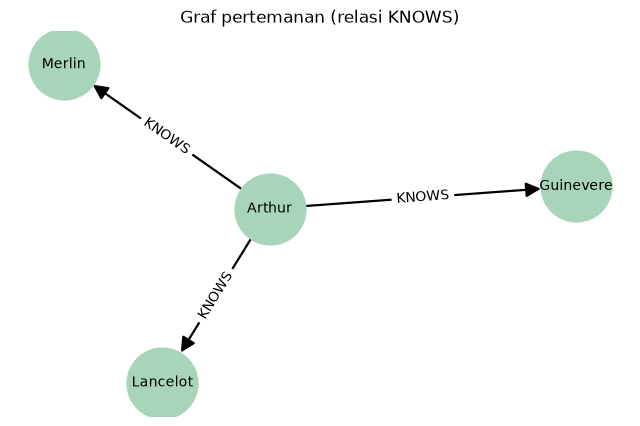

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase, RoutingControl

with GraphDatabase.driver(URI, auth=AUTH) as drv:
    records, _, _ = drv.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS dari, b.name AS ke",
        database_="neo4j", routing_=RoutingControl.READ,
    )

G = nx.DiGraph()
for r in records:
    G.add_edge(r["dari"], r["ke"])

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(8, 5))
nx.draw_networkx_nodes(G, pos, node_color="#a8d5ba", node_size=2600)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=22,
                       node_size=2600, width=1.6)
nx.draw_networkx_edge_labels(G, pos,
                             edge_labels={(u, v): "KNOWS" for u, v in G.edges()},
                             font_size=10)
plt.title("Graf pertemanan (relasi KNOWS)")
plt.axis("off")
plt.show()

In [4]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df.shape)
print(df["dt"].min(), "->", df["dt"].max())
print(df["event"].value_counts())
df.head()

(2756101, 6)
2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


Sel di atas membaca `events.csv` dan mengubah kolom `timestamp` (milidetik sejak epoch) menjadi kolom `dt` bertipe datetime. Dengan kolom ini, data bisa difilter berdasarkan tanggal. Output menunjukkan 2.756.101 baris dengan rentang 3 Mei sampai 18 September 2015, dan komposisi event: view 2.664.312, addtocart 69.332, dan transaction 22.457.

## Soal 2.1 No. 1: Dua periode waktu sebagai filter

Dua periode dipilih sebagai filter, sesuai daftar kombinasi yang ditentukan untuk UTS.

Periode pertama (P1) dipakai sebagai data training, yaitu 3 sampai 17 Mei 2015. Periode kedua (P2) dipakai sebagai data testing, yaitu 16 sampai 30 Juni 2015.

Kedua periode tidak tumpang tindih, karena P1 berakhir 17 Mei dan P2 dimulai 16 Juni. Keduanya berada di dalam rentang data yang tersedia, yaitu 3 Mei sampai 18 September 2015. Model dibangun dari P1 lalu diuji pada P2, sehingga rekomendasi tidak memakai informasi dari masa yang belum terjadi.

Catatan: P1 dimulai tepat pada tanggal awal data, jadi event pertama dataset ikut masuk ke training.

In [5]:
P1 = ("2015-05-03", "2015-05-17")   # training (3-17 Mei 2015)
P2 = ("2015-06-16", "2015-06-30")   # testing (16-30 Juni 2015)



## Soal 2.1 No. 2: Filter timestamp dan penyimpanan ke CSV

Fungsi `cut` mengambil baris yang waktunya berada dari awal hari `s` sampai akhir hari `e`. Batas akhir dihitung sebagai `e + 1 hari` dengan operator `<`, supaya seluruh hari terakhir ikut terhitung. Hasilnya disimpan ke dua file CSV, dan kolom `dt` dibuang sebelum disimpan agar file hanya memuat kolom asli.

Hasilnya, `events_p1.csv` berisi 296.319 baris (view 286.485, addtocart 7.430, transaction 2.404), dan `events_p2.csv` berisi 309.830 baris. Hanya `events_p1.csv` yang diimpor ke Neo4j. Data P2 dipakai sebagai ground truth saat evaluasi, sehingga data uji tidak bocor ke dalam graf.

In [6]:
def cut(d, s, e):
    return d[(d.dt >= s) & (d.dt < pd.Timestamp(e) + pd.Timedelta(days=1))]

train, test = cut(df, *P1), cut(df, *P2)
print("Baris P1:", len(train), "| Baris P2:", len(test))
print("Event P1:\n", train["event"].value_counts())

train.drop(columns="dt").to_csv("data/events_p1.csv", index=False)
test.drop(columns="dt").to_csv("data/events_p2.csv", index=False)
print("CSV tersimpan.")

Baris P1: 296319 | Baris P2: 309830
Event P1:
 event
view           286485
addtocart        7430
transaction      2404
Name: count, dtype: int64
CSV tersimpan.


## Soal 2.1 No. 3: Komposisi subgraph dengan Python API dan Cypher

Sebelum data diimpor, database dikosongkan dengan `MATCH (n) DETACH DELETE n`. Ini perlu karena `CREATE` pada relasi selalu menambah data baru, sehingga impor ulang tanpa penghapusan akan menggandakan relasi.

Fungsi `import_batch` memproses data per batch. `UNWIND $batch AS row` memecah list menjadi baris satu per satu. `WHERE row.event = $ev` memilih baris sesuai jenis event, sehingga setiap `tx.run` membuat satu jenis relasi. `MERGE` pada node memastikan setiap visitor dan item hanya dibuat satu kali, walaupun muncul di banyak event. `CREATE` pada relasi membuat satu relasi untuk setiap event. Batch berukuran 5.000 baris dipakai agar tidak mengirim data satu per satu, yang akan sangat lambat. Impor berjalan dalam 60 batch dan selesai dalam sekitar 1 menit.

In [7]:
import os
from tqdm import tqdm

csv_path = "data/events_p1.csv"
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"File '{csv_path}' tidak ditemukan. Jalankan sel filter P1/P2 dulu.")

# Kosongkan database dulu (aman: CREATE akan menggandakan data kalau diulang)
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    base = """
    UNWIND $batch AS row
    WITH row WHERE row.event = $ev
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    """
    tx.run(base + "CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)", batch=batch, ev="view")
    tx.run(base + "CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)", batch=batch, ev="addtocart")
    tx.run(base + "CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)", batch=batch, ev="transaction")

batch_size = 5_000
total_rows = sum(1 for _ in open(csv_path)) - 1
total_chunks = total_rows // batch_size + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    for chunk in tqdm(pd.read_csv(csv_path, chunksize=batch_size), total=total_chunks):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

print("Proses impor berhasil.")

100%|██████████| 60/60 [01:07<00:00,  1.12s/it]

Proses impor berhasil.


Query komposisi di bawah menjawab soal dengan Python API. Query pertama `MATCH (n)` mencocokkan semua node, `labels(n)[0]` mengambil label node, dan `count(*)` menghitung jumlahnya per label. Query kedua `MATCH ()-[r]->()` melakukan hal yang sama untuk relasi, dengan `type(r)` sebagai nama relasi. Driver mengembalikan hasil dalam bentuk record, dan `r.data()` mengubahnya menjadi dictionary agar bisa dimasukkan ke DataFrame.

Hasilnya, subgraph terdiri dari 155.916 node Visitor dan 78.171 node Item. Relasinya terdiri dari 286.485 VIEWED, 7.430 ADDED_TO_CART, dan 2.404 BOUGHT. Total relasi 296.319 sama dengan jumlah baris `events_p1.csv`, sehingga setiap event menjadi tepat satu relasi.

In [8]:
for q in ["MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah",
          "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"]:
    recs, _, _ = driver.execute_query(q, database_="neo4j")
    print(pd.DataFrame([r.data() for r in recs]), "\n")

     jenis  jumlah
0  Visitor  155916
1     Item   78171 

          relasi  jumlah
0         VIEWED  286485
1  ADDED_TO_CART    7430
2         BOUGHT    2404 



## Soal 2.1 No. 4: Vector Space Modelling terhadap user

Pertama, relasi diambil dari Neo4j dan duplikat pasangan (user, item) dibuang dengan `drop_duplicates()`. Satu user yang melakukan view lalu addtocart pada item yang sama dihitung sebagai satu hubungan. `pd.factorize` mengubah ID asli menjadi indeks 0, 1, 2, dan seterusnya, karena matriks membutuhkan indeks berurutan. Matriks `X` lalu dibentuk dengan `csr_matrix`, yaitu format sparse yang hanya menyimpan sel yang bernilai satu.

In [9]:
import numpy as np
from scipy.sparse import csr_matrix

q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i
"""
recs, _, _ = driver.execute_query(q, database_="neo4j")
edges = pd.DataFrame([r.data() for r in recs]).drop_duplicates().sort_values(["u", "i"]).reset_index(drop=True)

u_codes, user_ids = pd.factorize(edges["u"])
i_codes, item_ids = pd.factorize(edges["i"])

X = csr_matrix((np.ones(len(edges)), (u_codes, i_codes)),
               shape=(len(user_ids), len(item_ids)))
print("Matriks user-item X:", X.shape)

Matriks user-item X: (155916, 78171)


Setiap user direpresentasikan sebagai vektor dengan panjang sama dengan jumlah item, yaitu 78.171. Matriks berukuran 155.916 kali 78.171 dengan 231.267 elemen bernilai satu. Dari seluruh kemungkinan sel, hanya sekitar 0,0019% yang terisi, sehingga density-nya 1,90×10⁻⁵. Representasi sparse wajib dipakai karena matriks padat akan memakan memori yang sangat besar.

Rata-rata setiap user berinteraksi dengan 1,48 item, dengan median 1 dan maksimum 487. Sebanyak 80,69% user hanya berinteraksi dengan satu item. Distribusi ini sangat miring: mayoritas user hanya punya satu item, sementara sebagian kecil user sangat aktif.

In [10]:
n_users, n_items = X.shape
deg_user = np.asarray(X.sum(axis=1)).ravel()   # jumlah item per user

print("Dimensi vektor user :", n_items)
print("Jumlah vektor user  :", n_users)
print("Shape               :", X.shape)
print("Elemen non-nol      :", X.nnz)
print("Density             :", X.nnz / (n_users * n_items))
print("Rata-rata item/user :", deg_user.mean(), "| median:", np.median(deg_user), "| maks:", deg_user.max())
print("User dengan 1 item  :", (deg_user == 1).mean() * 100, "%")

Dimensi vektor user : 78171
Jumlah vektor user  : 155916
Shape               : (155916, 78171)
Elemen non-nol      : 231267
Density             : 1.8974804699566128e-05
Rata-rata item/user : 1.4832794581697837 | median: 1.0 | maks: 487.0
User dengan 1 item  : 80.68511249647246 %


## Soal 2.1 No. 5: Vector Space Modelling terhadap item

Transpos `X` menghasilkan matriks item-user, `XT`, di mana setiap baris adalah satu item dengan dimensi sepanjang jumlah user, yaitu 155.916. Density-nya sama dengan sisi user karena jumlah elemen non-nolnya tetap 231.267.

Perbedaannya ada pada distribusi. Rata-rata user per item adalah 2,96, lebih tinggi daripada rata-rata item per user yang 1,48. Artinya item lebih sering disentuh oleh beberapa user sekaligus. Item paling populer disentuh oleh 370 user. Meski begitu, 55,24% item tetap hanya disentuh satu user.

In [11]:
XT = X.T.tocsr()
deg_item = np.asarray(X.sum(axis=0)).ravel()   # jumlah user per item

print("Dimensi vektor item :", n_users)
print("Jumlah vektor item  :", n_items)
print("Shape               :", XT.shape)
print("Density             :", XT.nnz / (n_users * n_items))
print("Rata-rata user/item :", deg_item.mean(), "| median:", np.median(deg_item), "| maks:", deg_item.max())
print("Item dengan 1 user  :", (deg_item == 1).mean() * 100, "%")

Dimensi vektor item : 155916
Jumlah vektor item  : 78171
Shape               : (78171, 155916)
Density             : 1.8974804699566128e-05
Rata-rata user/item : 2.958475649537552 | median: 1.0 | maks: 370.0
Item dengan 1 user  : 55.239155185426824 %


Sel plot di bawah menggambarkan karakteristik untuk No. 4 dan No. 5 sekaligus. Bagian pertama menampilkan 15 user acak yang punya 3 sampai 8 item, dengan 74 node dan 60 edge. Hasilnya berupa klaster bintang kecil yang saling terpisah. Setiap user (biru) terhubung ke item-itemnya (oranye), tetapi tidak ada dua user yang terhubung langsung. Ini adalah graf bipartit, sehingga kemiripan antar user belum terlihat dan perlu diproyeksikan dulu.

Bagian kedua menampilkan 8 item acak yang punya 5 sampai 15 user, dengan 76 node dan 68 edge. Polanya sama: klaster kecil yang terpisah dengan struktur bipartit.

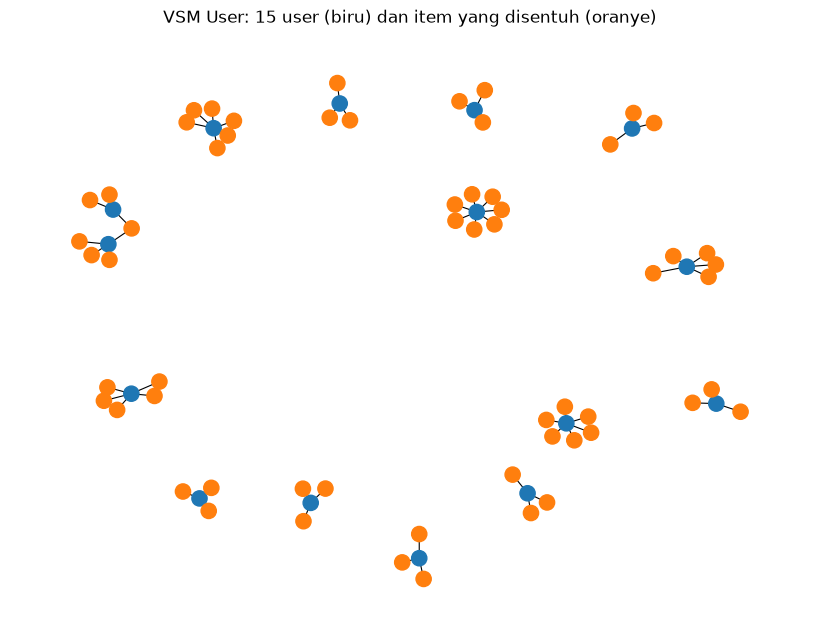

Node: 74 | Edge: 60


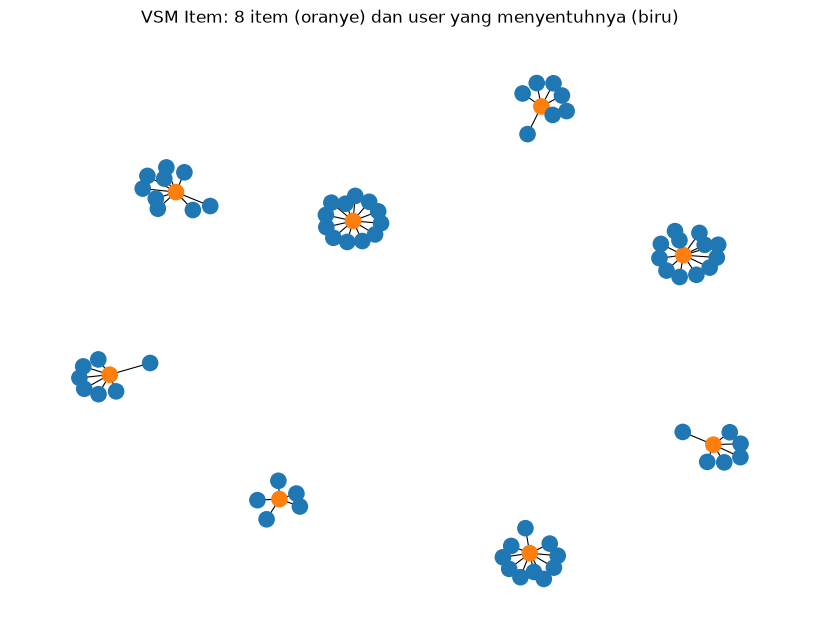

Node: 76 | Edge: 68


In [12]:
import networkx as nx, matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def gambar(sub, judul):
    G = nx.Graph()
    G.add_edges_from(zip("U" + sub["u"].astype(str), "I" + sub["i"].astype(str)))
    warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G]
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, node_color=warna, node_size=120, width=0.8)
    plt.title(judul); plt.show()
    print("Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges())

# No. 4: berpusat pada User
pick_u = rng.choice(np.where((deg_user >= 3) & (deg_user <= 8))[0], 15, replace=False)
gambar(edges[edges["u"].isin(user_ids[pick_u])], "VSM User: 15 user (biru) dan item yang disentuh (oranye)")

# No. 5: berpusat pada Item
pick_i = rng.choice(np.where((deg_item >= 5) & (deg_item <= 15))[0], 8, replace=False)
gambar(edges[edges["i"].isin(item_ids[pick_i])], "VSM Item: 8 item (oranye) dan user yang menyentuhnya (biru)")

## Soal 2.1 No. 6: Pemilihan proyeksi

Sel di bawah menghitung batas atas jumlah relasi untuk kedua proyeksi. Sebuah item yang disentuh `d` user menciptakan hingga `d²` pasangan user-user, sehingga `(deg_item ** 2).sum()` memberi batas atas proyeksi user-user. Logika yang sama berlaku untuk item-item dengan `deg_user`.

In [13]:
pairs_uu = (deg_item ** 2).sum()   # batas atas pasangan user-user
pairs_ii = (deg_user ** 2).sum()   # batas atas pasangan item-item

print("Proyeksi user-user : %d node, maks sekitar %.2e relasi" % (n_users, pairs_uu))
print("Proyeksi item-item : %d node, maks sekitar %.2e relasi" % (n_items, pairs_ii))

Proyeksi user-user : 155916 node, maks sekitar 3.31e+06 relasi
Proyeksi item-item : 78171 node, maks sekitar 2.48e+06 relasi


Kedua proyeksi dibentuk dari matriks `X`. Proyeksi item-item adalah XᵀX, sedangkan proyeksi user-user adalah XXᵀ. Diagonal dibuang agar node tidak terhubung dengan dirinya sendiri, dan relasinya dihitung tak berarah. Entri `(i, j)` pada XᵀX adalah jumlah user yang menyentuh kedua item tersebut.

Proyeksi item-item memiliki 78.171 node dan 1.074.261 relasi, dengan density 3,52×10⁻⁴. Proyeksi user-user memiliki 155.916 node dan 1.489.900 relasi, dengan density 1,23×10⁻⁴.

Proyeksi item-item dipilih karena tiga alasan. Pertama, jumlah node-nya sekitar setengah dari user-user, sehingga lebih efisien dari sisi memori dan waktu. Kedua, density-nya sekitar 2,9 kali lebih tinggi, sehingga setiap item punya lebih banyak tetangga yang informatif. Ketiga, 80,69% user hanya berinteraksi dengan satu item, sehingga vektor user hampir tidak tumpang tindih dan proyeksi user-user kurang informatif. Kelemahannya, 55,24% item juga hanya disentuh satu user, sehingga sebagian item tetap tidak punya tetangga dalam graf.

In [14]:
C_ii = (XT @ X).tocsr(); C_ii.setdiag(0); C_ii.eliminate_zeros()   # item-item
C_uu = (X @ XT).tocsr(); C_uu.setdiag(0); C_uu.eliminate_zeros()   # user-user

print("Item-item: node", C_ii.shape[0], "| relasi (tak berarah):", C_ii.nnz // 2,
      "| density:", C_ii.nnz / C_ii.shape[0]**2)
print("User-user: node", C_uu.shape[0], "| relasi (tak berarah):", C_uu.nnz // 2,
      "| density:", C_uu.nnz / C_uu.shape[0]**2)


Item-item: node 78171 | relasi (tak berarah): 1074261 | density: 0.00035159967880375135
User-user: node 155916 | relasi (tak berarah): 1489900 | density: 0.00012257608518835304




## Soal 2.1 No. 7: Similarity pada graf terproyeksi

Item acuan dipilih sebagai item paling populer, yaitu item 369447 yang disentuh 370 user. Sel di bawah mencari nilai ID-nya.

In [15]:
ref_idx = int(np.argmax(deg_item))
ref_item = int(item_ids[ref_idx])


Sel di bawah menghitung cosine similarity secara manual dari proyeksi item-item. Baris `row` berisi jumlah user yang sama-sama menyentuh item acuan dan setiap item lain. Untuk data biner, cosine similarity sama dengan jumlah user bersama dibagi akar dari hasil kali jumlah user masing-masing item. `cos[ref_idx] = -1` menyingkirkan item acuan dari daftar agar tidak dihitung mirip dengan dirinya sendiri.

Lima item dengan similarity tertinggi terhadap item 369447 adalah 274435 (0,3004), 356129 (0,2805), 379935 (0,1995), 257597 (0,1891), dan 150882 (0,1279).

In [16]:
# Similarity dari graf terproyeksi (item acuan yang sama)
row = C_ii[ref_idx].toarray().ravel()
cos = row / np.sqrt(deg_item[ref_idx] * deg_item)
cos[ref_idx] = -1
top = np.argsort(-cos)[:5]
print(pd.DataFrame({"id": item_ids[top], "score": cos[top]}))

       id     score
0  274435  0.300406
1  356129  0.280546
2  379935  0.199508
3  257597  0.189132
4  150882  0.127872


Sel di bawah menghitung hasil yang sama menggunakan `cosine_similarity` dari scikit-learn sebagai pembanding. Daftar hasilnya identik dengan perhitungan manual di atas, sehingga rumus yang dipakai sudah benar. Variabel `rows` yang dihasilkan sel ini dipakai lagi pada langkah penulisan ke graf.

In [17]:
from sklearn.metrics.pairwise import cosine_similarity

sims = cosine_similarity(XT[ref_idx], XT).ravel()
sims[ref_idx] = -1
top = np.argsort(-sims)[:5]
rows = [{"id": int(item_ids[j]), "score": float(sims[j])} for j in top]
print("Item acuan:", ref_item)
print(pd.DataFrame(rows))

Item acuan: 369447
       id     score
0  274435  0.300406
1  356129  0.280546
2  379935  0.199508
3  257597  0.189132
4  150882  0.127872


### (a) Query Cypher untuk 5 record similarity tertinggi

Query di bawah menghitung similarity langsung di Neo4j. Baris pertama mencari item lain `b` yang disentuh user yang sama dengan item acuan `a`, lalu `count(DISTINCT v)` menghitung irisan user, yaitu `inter`. Dua baris `MATCH` berikutnya menghitung `na` dan `nb`, yaitu jumlah user unik masing-masing item. Rumus `inter / sqrt(na · nb)` adalah cosine similarity untuk data biner. `toFloat` dipakai agar pembagian tidak terpotong menjadi bilangan bulat. `ORDER BY ... LIMIT 5` mengambil lima hasil teratas, yang sama dengan hasil Python.

In [18]:
q = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
      -[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE a <> b
WITH a, b, count(DISTINCT v) AS inter
MATCH (a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(va:Visitor)
WITH a, b, inter, count(DISTINCT va) AS na
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(vb:Visitor)
WITH a, b, inter, na, count(DISTINCT vb) AS nb
RETURN b.itemId AS tetangga, inter / sqrt(toFloat(na) * nb) AS cosine
ORDER BY cosine DESC LIMIT 5
"""
recs, _, _ = driver.execute_query(q, ref=ref_item, database_="neo4j")
print(pd.DataFrame([r.data() for r in recs]))

   tetangga    cosine
0    274435  0.300406
1    356129  0.280546
2    379935  0.199508
3    257597  0.189132
4    150882  0.127872


In [19]:
recs, _, _ = driver.execute_query(
    "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS jumlah", database_="neo4j")
print("SIMILAR_TO sebelum:", recs[0]["jumlah"])   # harus 0

SIMILAR_TO sebelum: 0


### Graf sebelum (soal No. 8)

Sel di bawah mengambil sampel visitor yang menyentuh item acuan (maksimum 15 relasi, pada output ini 11 visitor unik) dan menggambarnya dengan networkx. Pada kondisi ini belum ada relasi `SIMILAR_TO`, sehingga item acuan (kuning) hanya terhubung ke visitor (biru). Jalankan sel ini sebelum sel penulisan.

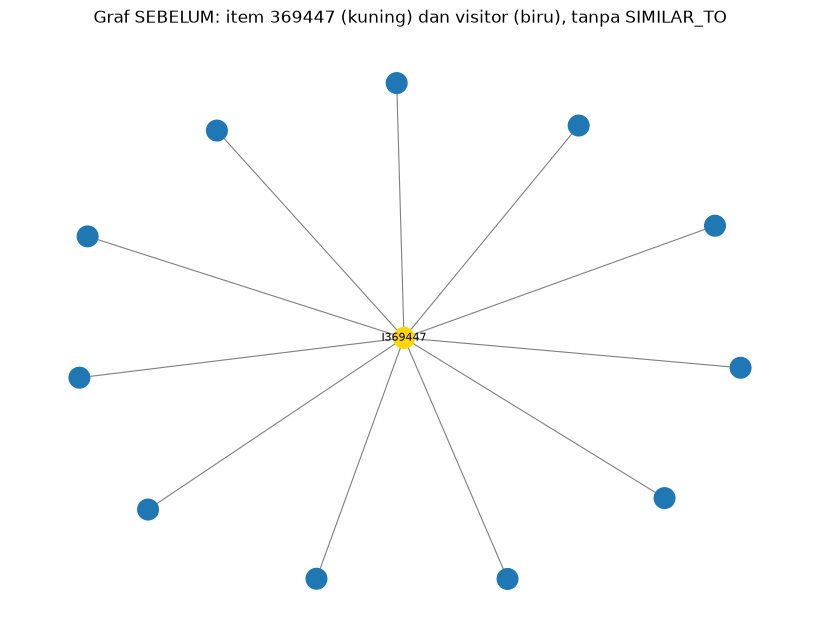

Node: 12 | Edge: 11 | SIMILAR_TO: 0


In [20]:
def ambil_graf(ref, batas=15):
    """Ambil visitor yang menyentuh item acuan (sampel) dan semua relasi SIMILAR_TO-nya."""
    q_v = """
    MATCH (v:Visitor)-[r]->(a:Item {itemId: $ref})
    RETURN a.itemId AS a, type(r) AS rel, 'Visitor' AS jenis, v.visitorId AS x
    ORDER BY v.visitorId LIMIT $batas
    """
    q_s = """
    MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemId AS a, type(s) AS rel, 'Item' AS jenis, b.itemId AS x, s.score AS score
    """
    v, _, _ = driver.execute_query(q_v, ref=ref, batas=batas, database_="neo4j")
    s, _, _ = driver.execute_query(q_s, ref=ref, database_="neo4j")
    return pd.DataFrame([r.data() for r in v] + [r.data() for r in s])

def gambar_graf(d, judul, pos=None):
    G = nx.Graph()
    pusat = f"I{ref_item}"
    G.add_node(pusat)
    for _, r in d.iterrows():
        n = ("V" if r["jenis"] == "Visitor" else "I") + str(r["x"])
        G.add_edge(pusat, n, rel=r["rel"])
    warna = ["gold" if n == pusat else ("tab:blue" if n.startswith("V") else "tab:green") for n in G]
    garis = ["red" if G[u][v]["rel"] == "SIMILAR_TO" else "gray" for u, v in G.edges]
    lebar = [2.5 if c == "red" else 0.8 for c in garis]
    if pos is None:
        pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, node_color=warna, edge_color=garis, width=lebar, node_size=220,
            with_labels=True, labels={n: n for n in G if not n.startswith("V")}, font_size=8)
    plt.title(judul); plt.show()
    print("Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges(),
          "| SIMILAR_TO:", int((d["rel"] == "SIMILAR_TO").sum()))
    return pos

sebelum = ambil_graf(ref_item)
n_sim_sebelum = int((sebelum["rel"] == "SIMILAR_TO").sum())
pos_graf = gambar_graf(sebelum, f"Graf SEBELUM: item {ref_item} (kuning) dan visitor (biru), tanpa SIMILAR_TO")

### (b) Menulis similarity kembali ke graf

Sel penulisan ada di bawah. Sebelum dijalankan, kondisi "sebelum" sudah direkam di dua sel di atas: jumlah `SIMILAR_TO` adalah 0 dan graf item acuan sudah digambar.

Sel penulisan menyimpan lima hasil similarity sebagai relasi `SIMILAR_TO`. `UNWIND $rows` memproses lima hasil satu per satu. `MERGE` membuat relasi hanya jika belum ada, sehingga menjalankan sel ini dua kali tidak menghasilkan duplikasi. `SET s.score` menyimpan nilai similarity sebagai properti relasi.

In [21]:
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: r.id})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
""", rows=rows, ref=ref_item, database_="neo4j")
print("SIMILAR_TO ditulis.")

SIMILAR_TO ditulis.




Sel di bawah memverifikasi hasil penulisan. Lima relasi dari item 369447 muncul dengan skor yang sama seperti hasil perhitungan.

In [22]:
recs, _, _ = driver.execute_query("""
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS dari, b.itemId AS ke, s.score AS score
ORDER BY score DESC
LIMIT 5
""", database_="neo4j")
print(pd.DataFrame([r.data() for r in recs]))

     dari      ke     score
0  369447  274435  0.300406
1  369447  356129  0.280546
2  369447  379935  0.199508
3  369447  257597  0.189132
4  369447  150882  0.127872


### Graf sesudah (soal No. 8)

Sel di bawah menggambar ulang graf di sekitar item acuan setelah `SIMILAR_TO` ditulis. Lima item mirip muncul sebagai node hijau yang terhubung dengan garis merah, dan tabel di bawahnya membandingkan jumlah `SIMILAR_TO` sebelum dan sesudah.

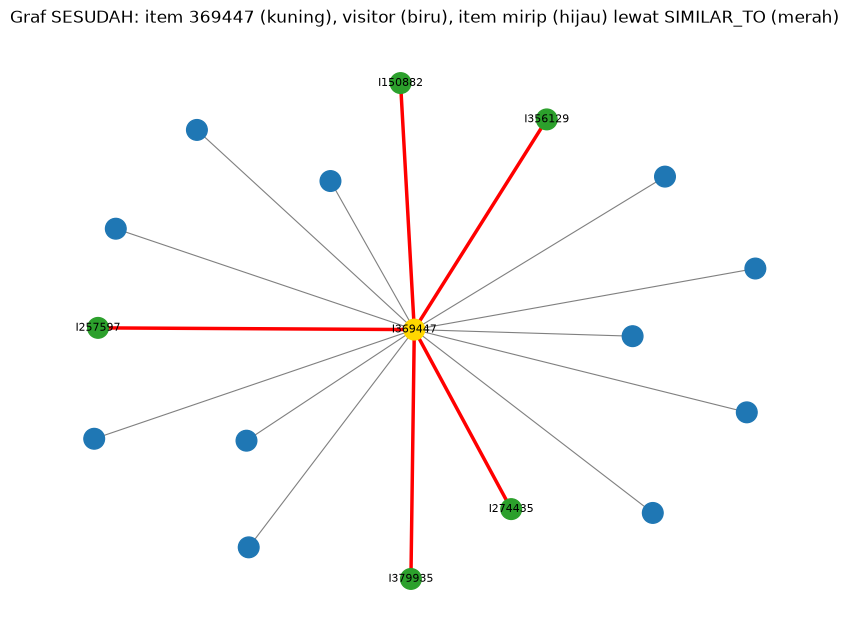

Node: 17 | Edge: 16 | SIMILAR_TO: 5
   Kondisi  Relasi SIMILAR_TO
0  Sebelum                  0
1  Sesudah                  5
      dari      ke     score
15  369447  356129  0.280546
16  369447  257597  0.189132
17  369447  379935  0.199508
18  369447  274435  0.300406
19  369447  150882  0.127872


In [23]:
sesudah = ambil_graf(ref_item)
n_sim_sesudah = int((sesudah["rel"] == "SIMILAR_TO").sum())
gambar_graf(sesudah, f"Graf SESUDAH: item {ref_item} (kuning), visitor (biru), item mirip (hijau) lewat SIMILAR_TO (merah)")

print(pd.DataFrame({
    "Kondisi": ["Sebelum", "Sesudah"],
    "Relasi SIMILAR_TO": [n_sim_sebelum, n_sim_sesudah],
}))
print(sesudah[sesudah["rel"] == "SIMILAR_TO"][["a", "x", "score"]].rename(columns={"a": "dari", "x": "ke"}))

## Soal 2.1 No. 8: Kondisi graf sebelum dan sesudah similarity

**Sebelum.** Jumlah relasi `SIMILAR_TO` adalah 0. Graf di sekitar item acuan 369447 hanya berisi visitor yang menyentuh item itu lewat relasi `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`. Gambar networkx pada sel "Graf sebelum" memperlihatkan kondisi ini (sampel 11 visitor unik).

**Sesudah.** Setelah penulisan, ada 5 relasi `SIMILAR_TO` dari item 369447 ke item 274435, 356129, 379935, 257597, dan 150882, masing-masing membawa properti `score`. Gambar networkx pada sel "Graf sesudah" menampilkan visitor yang sama ditambah lima item tetangga lewat garis merah `SIMILAR_TO`, dan tabel ringkasan membandingkan kedua kondisi.

Query Cypher untuk melihat kedua kondisi di Neo4j Query (teksnya dicetak oleh sel di bawah):

- Sebelum: `MATCH (a:Item {itemId: 369447})<-[r]-(v:Visitor) RETURN a, r, v LIMIT 25`
- Sesudah: `MATCH (a:Item {itemId: 369447})-[s:SIMILAR_TO]->(b:Item) RETURN a, b, s`



In [24]:
print(f"Sebelum: MATCH (a:Item {{itemId: {ref_item}}})<-[r]-(v:Visitor) RETURN a, r, v LIMIT 25")
print(f"Sesudah: MATCH (a:Item {{itemId: {ref_item}}})-[s:SIMILAR_TO]->(b:Item) RETURN a, b, s")

Sebelum: MATCH (a:Item {itemId: 369447})<-[r]-(v:Visitor) RETURN a, r, v LIMIT 25
Sesudah: MATCH (a:Item {itemId: 369447})-[s:SIMILAR_TO]->(b:Item) RETURN a, b, s




## Soal 2.2 No. 1a: Skrip KNN untuk satu user

Sel di bawah memilih satu user secara acak dan merekomendasikan item dengan KNN berbasis item.

Pemilihan dilakukan dengan `default_rng(42)`, sehingga hasilnya selalu sama setiap kali dijalankan. Sebelum dipilih, kandidat disaring terlebih dahulu: user harus punya minimal dua item di P1 dan punya item baru di P2. Syarat ini perlu agar evaluasi bermakna, karena jika user tidak punya item baru di P2, tidak ada yang bisa diukur. Dari 1.126 kandidat, terpilih user 105532, yang punya 2 item di P1.

Algoritmanya bekerja seperti ini. Untuk setiap item yang sudah disentuh user, dicari K = 5 tetangga terdekat berdasarkan cosine similarity. Skor setiap tetangga dijumlahkan ke skor kandidat, sehingga item yang mirip dengan beberapa item milik user mendapat skor lebih tinggi. Item yang sudah pernah disentuh dibuang dari daftar, lalu lima skor tertinggi diambil.

In [25]:
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
K = 5

pos_user = {int(u): idx for idx, u in enumerate(user_ids)}
test_gt = test.groupby("visitorid")["itemid"].apply(set)
ids = np.asarray(item_ids)                 # ID item, dipakai untuk memecah skor seri

# Kandidat: user ada di P1 (punya >=2 item) dan di P2 punya item BARU
# (item di P2 yang belum pernah disentuh di P1), supaya bisa dievaluasi
cands = []
for u in sorted(set(train["visitorid"]) & set(test["visitorid"])):
    if u not in pos_user:
        continue
    seen = set(item_ids[X[pos_user[u]].indices])
    if len(seen) >= 2 and len(test_gt[u] - seen) > 0:
        cands.append(u)

print("Jumlah kandidat user:", len(cands))
target = int(np.random.default_rng(SEED).choice(cands))
u_idx = pos_user[target]
seen_idx = X[u_idx].indices               # indeks item yang disentuh user di P1
print("User terpilih:", target, "| item di P1:", len(seen_idx))

# KNN: top-K tetangga untuk tiap item yang disentuh user
S = cosine_similarity(XT[seen_idx], XT)   # (jumlah item user) x (semua item)
S[np.arange(len(seen_idx)), seen_idx] = 0 # buang similarity ke diri sendiri
scores = np.zeros(S.shape[1])
for row in S:
    nn = np.lexsort((ids, -row))[:K]      # skor menurun; skor seri diurutkan item ID naik
    scores[nn] += row[nn]
scores[seen_idx] = -1                      # jangan rekomendasikan yang sudah dilihat

top5_idx = np.lexsort((ids, -scores))[:5] # skor menurun; skor seri diurutkan item ID naik
rec = [int(item_ids[j]) for j in top5_idx]
print("Top-5 rekomendasi:", rec)
print("3 item yang diiklankan:", rec[:3])

Jumlah kandidat user: 1126
User terpilih: 105532 | item di P1: 2
Top-5 rekomendasi: [193753, 310510, 455935, 301359, 230439]
3 item yang diiklankan: [193753, 310510, 455935]


## Soal 2.2 No. 1b: Tiga item yang diiklankan untuk k = 5


Lima rekomendasi teratas untuk user 105532 adalah 193753 (skor 0,8165), 310510 (0,8165), 455935 (0,8165), 301359 (0,4082), dan 230439 (0,3333).

**Tiga item yang diiklankan adalah 193753, 310510, dan 455935.**

Kelima item memiliki skor di atas nol. Tiga item teratas berskor sama, sehingga skor seri diurutkan berdasarkan item ID naik agar hasilnya reproducible (tanpa aturan ini, urutan di antara ketiganya bisa berubah antar-run). User ini hanya punya 2 item di P1, jadi skor berasal dari sedikit tetangga.


## Soal 2.2 No. 2: Hit@5 dan NDCG@5

Ground truth untuk user 105532 di P2 adalah {359529, 75767, 194596, 314079}, yaitu empat item baru yang belum pernah disentuh user di P1. Sel di bawah menghitung Hit@5 dan NDCG@5.

Hit@5 bernilai 1 jika setidaknya satu dari lima rekomendasi ada di ground truth, dan 0 jika tidak. NDCG@5 memberi bobot lebih tinggi untuk hit di peringkat atas. `log2(r + 2)` mengubah indeks berbasis 0 menjadi bobot posisi, dan pembagian dengan IDCG menormalkan nilainya ke rentang 0 sampai 1.

In [26]:
seen_items = set(item_ids[seen_idx])
gt = test_gt[target] - seen_items          # ground truth: item baru di P2
print("Ground truth P2:", gt)

hit = int(any(i in gt for i in rec))
dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec) if i in gt)
idcg = sum(1 / np.log2(r + 2) for r in range(min(len(gt), 5)))
ndcg = dcg / idcg if idcg > 0 else 0.0

print("Hit@5  :", hit)
print("NDCG@5 :", round(ndcg, 4))

Ground truth P2: {359529, 75767, 194596, 314079}
Hit@5  : 0
NDCG@5 : 0.0


Hasilnya, Hit@5 = 0 dan NDCG@5 = 0. Tidak ada satu pun dari lima rekomendasi (193753, 310510, 455935, 301359, 230439) yang termasuk ground truth.

Pemeriksaan keempat item ground truth menunjukkan dua penyebab berbeda:

- **Cold-start (item 75767 dan 314079).** Kedua item tidak ada di graf P1, karena baru muncul di P2. Model berbasis similarity hanya dapat merekomendasikan item yang sudah punya data interaksi, sehingga kedua item ini mustahil masuk rekomendasi.
- **Ada di graf tetapi berskor 0 (item 194596 dan 359529).** Item 194596 disentuh 6 user dan item 359529 disentuh 1 user di P1. Skor 0 berarti kedua item tidak masuk top-K tetangga dari item milik user terpilih. Sel berikut memeriksa nilai similarity dan jumlah user bersama untuk kedua item.

Selain itu, user terpilih hanya punya 2 item di P1, sehingga sinyal yang tersedia sangat sedikit dan data sangat sparse.

In [27]:
for t in sorted(gt):
    if t in set(item_ids):
        j = int(np.where(item_ids == t)[0][0])
        print(t, "| ada di graf P1 | user di P1:", int(deg_item[j]), "| skor:", scores[j])
    else:
        print(t, "| tidak ada di graf P1 (cold-start)")

75767 | tidak ada di graf P1 (cold-start)
194596 | ada di graf P1 | user di P1: 6 | skor: 0.0
314079 | tidak ada di graf P1 (cold-start)
359529 | ada di graf P1 | user di P1: 1 | skor: 0.0


In [28]:
for t in [194596, 359529]:
    j = int(np.where(item_ids == t)[0][0])
    sim_ke_item_user = S[:, j]
    bersama = (XT[seen_idx] @ XT[j].T).toarray().ravel()
    print(t, "| similarity ke tiap item user:", np.round(sim_ke_item_user, 4),
          "| user bersama dengan tiap item user:", bersama)

194596 | similarity ke tiap item user: [0. 0.] | user bersama dengan tiap item user: [0. 0.]
359529 | similarity ke tiap item user: [0. 0.] | user bersama dengan tiap item user: [0. 0.]


Pemeriksaan menunjukkan kedua item tidak disentuh bersama dengan item milik user terpilih oleh user mana pun (user bersama = 0). Similarity keduanya 0, sehingga keduanya tidak mendapat skor dari KNN.

In [29]:
print("Jumlah item dengan skor > 0:", int((scores > 0).sum()))
print("Item user terpilih di P1:", len(seen_idx))

Jumlah item dengan skor > 0: 5
Item user terpilih di P1: 2


In [30]:
print("Skor top-5:", [round(float(scores[j]), 4) for j in top5_idx])

Skor top-5: [0.8165, 0.8165, 0.8165, 0.4082, 0.3333]


Hasil ini hanya berasal dari satu user, sehingga Hit@5 dan NDCG@5 di sini bersifat biner dan tidak cukup untuk menilai kualitas model secara umum. Evaluasi yang lebih andal adalah menghitung kedua metrik untuk seluruh 1.126 user kandidat, lalu mengambil rata-ratanya.